# 05. LLM을 Node에 연결하기
## 학습 목표
- `ChatOpenAI` 단독 호출과 Graph 내부 호출을 비교한다.
- 질문과 응답을 State에 보관한다.

**준비:** `OPENAI_API_KEY`가 필요하다. 기본 모델은 `gpt-4o-mini`이다. 각 실습은 API 요청을 한 번 수행하므로 비용이 발생할 수 있다.

## 핵심 개념·실행 전 예측
LLM은 입력 메시지를 받아 답을 만든다. LangGraph는 LLM 자체가 아니라 그 호출 순서와 State 흐름을 구성한다. 같은 질문을 두 방식으로 호출하면 응답 문구가 반드시 완전히 같을까?

In [1]:
import os
from common.ai_model import get_llm_model

llm_options = {"model": "gpt-4o-mini", "temperature": 0}

llm = get_llm_model(**llm_options)
print("사용 모델:", llm_options["model"])

ImportError: cannot import name 'LLM_API_KEY' from 'common.config' (/home/aiuser/rag_agent_ex/common/config.py)

In [14]:
question = "LangGraph의 State를 한 문장으로 설명해줘."

# 파일 캐시에서 있으면 가져오고, 없으면 LLM을 호출하여 답변을 가져온다.
import os
os.makedirs("llm_result", exist_ok=True)
cache_file = "llm_result/state_description_cache.txt"
if os.path.exists(cache_file):
    with open(cache_file, "r", encoding="utf-8") as f:
        direct_answer = f.read().strip()
else:
    direct_answer = llm.invoke(question).content

    # LLM 호출 결과를 캐시에 저장
    with open(cache_file, "w", encoding="utf-8") as f:
        f.write(direct_answer)

In [11]:
print("LangChain 단독 응답:\n", direct_answer)

LangChain 단독 응답:
 LangGraph의 State는 언어 모델의 현재 상태를 나타내며, 입력된 텍스트와 그에 대한 처리 결과를 기반으로 다음 단계를 결정하는 데 사용됩니다.


# 그래프 그리기

In [20]:
from pydantic import BaseModel
from langgraph.graph import START, END, StateGraph

# State 스키마 정의
class QAState(BaseModel):
    question: str
    answer: str

# Node 정의
def llm_node(state: QAState) -> dict:
    # Node는 입력 State의 질문을 사용하고 응답만 업데이트한다.
    response = llm.invoke(state.question)
    return {"answer": response.content}


# Graph 빌더 생성 및 Node, Edge 추가
builder = StateGraph(QAState)
builder.add_node("llm_node", llm_node)
builder.add_edge(START, "llm_node")
builder.add_edge("llm_node", END)

# Graph 컴파일
graph = builder.compile()

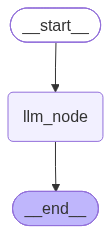

In [ ]:
# 그래프 그리기
from common.utils import visualize_graph
visualize_graph(graph)

In [26]:
question = "LangGraph의 State를 한 문장으로 설명해줘."
result = graph.invoke({"question": question, "answer": ""})

In [27]:
print("질문:", result["question"])
print("Graph 응답:", result["answer"])
assert result["question"] == question and bool(result["answer"])

질문: LangGraph의 State를 한 문장으로 설명해줘.
Graph 응답: LangGraph의 State는 언어 모델의 현재 상태를 나타내며, 입력된 텍스트와 그에 대한 처리 결과를 기반으로 다음 단계를 결정하는 데 사용됩니다.


`temperature=0`이어도 API 호출마다 문구가 같다고 보장되지는 않는다. 비교할 대상은 문자열의 완전 일치보다 **호출 경로와 State 저장 위치**이다.

## 작은 수정 실습
질문을 "Node와 Edge의 차이를 한 문장으로 설명해줘"로 바꾸어 Graph를 한 번만 더 실행한다. 어떤 필드가 입력이고 어떤 필드가 업데이트인지 표시한다.

## 이해 확인
1. `llm_node`가 `question`을 반환하지 않아도 최종 State에 남는 이유는 무엇인가?  
   **해설:** 반환된 `answer`만 덮어쓰고 나머지 State는 유지된다.
2. LangGraph가 답변을 생성하는 모델인가?  
   **해설:** 아니다. 답변은 `ChatOpenAI`가 생성하고 Graph는 실행과 State 이동을 관리한다.

**핵심 정리:** LLM을 Node 내부에 배치하면 모델 응답을 Graph State의 일부로 저장하고 다음 단계로 전달할 수 있다.